# Evaluación 02 — Del CSV al Parquet y clasificación con clases desbalanceadas

Asignatura: Machine Learning · Universidad Bernardo O’Higgins - Gerardo González

## Qué se hace en este notebook

1. Se compara el archivo CSV con el archivo Parquet (peso en disco, tiempo de lectura y memoria).
2. Se arma el conjunto de datos de tres rubros y se divide en Train, Validation y Test por orden de compra.
3. Se entrena un modelo CatBoost "normal" y se prueban tres métodos para el desbalance de clases: pesos de clase, SMOTENC y ajuste del umbral.
4. Se elige el mejor modelo con el F1 macro en Validation y recién después se mira Test una sola vez.
5. Se revisan errores, variables importantes y se escribe la conclusión.


# 0. Entorno y configuración

La primera celda instala las librerías y muestra las versiones usadas (la memoria que mide pandas cambia según la versión).

In [ ]:
!pip install -q pandas pyarrow scikit-learn catboost imbalanced-learn matplotlib

import sys, os, gc, json, time, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow
import sklearn
import catboost
import imblearn
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("pyarrow:", pyarrow.__version__)
print("scikit-learn:", sklearn.__version__)
print("CatBoost:", catboost.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("matplotlib:", matplotlib.__version__)

Python: 3.13.16
pandas: 2.2.3
pyarrow: 23.0.1
scikit-learn: 1.6.1
CatBoost: 1.2.10
imbalanced-learn: 0.14.2
matplotlib: 3.10.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0.1 Configuración general

Las opciones del trabajo quedan reunidas en una sola celda:

* USAR_GPU = False: se usa solo el procesador, como pide la evaluación. Si se cambia a True se usa GPU, y en ese caso queda igual para los cuatro modelos.
* REENTRENAR = False: evita volver a entrenar un modelo que ya quedó guardado en la carpeta modelos. Así, si se corta la sesión, no se pierde el trabajo. Con True se entrena todo de nuevo.
* Todas las rutas son relativas (carpetas datos y modelos junto al notebook).


In [ ]:
SEMILLA = 42
USAR_GPU = False
REENTRENAR = False

CARPETA_DATOS = Path("datos")
CARPETA_MODELOS = Path("modelos")
CARPETA_DATOS.mkdir(exist_ok=True)
CARPETA_MODELOS.mkdir(exist_ok=True)

RUTA_CSV = CARPETA_DATOS / "2026-1.csv"
RUTA_PARQUET = CARPETA_DATOS / "2026-1.parquet"

# Lo que queremos predecir y las tres clases permitidas
TARGET = "RubroN1"
CLASES = [
    "Equipamiento y suministros médicos",
    "Alimentos, bebidas y tabaco",
    "Medicamentos y productos farmacéuticos",
]
CORTO = {  # nombres cortos solo para que los gráficos se lean bien
    "Equipamiento y suministros médicos": "Equipamiento",
    "Alimentos, bebidas y tabaco": "Alimentos",
    "Medicamentos y productos farmacéuticos": "Medicamentos",
}
CLASE_INTERES = "Medicamentos y productos farmacéuticos"

# Las únicas variables que entran al modelo
CATEGORICAL_FEATURES = ["Tipo", "sector", "RegionUnidadCompra", "RegionProveedor",
                        "UnidadMedida", "TipoImpuesto", "monedaItem"]
NUMERIC_FEATURES = ["cantidad", "precioNeto", "totalLineaNeto", "MontoTotalOC_PesosChilenos"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

# Columnas que se leen del archivo: las 11 variables + el target + 3 columnas que NO entran al modelo
#   Codigo e IDItem: sirven para dividir por orden y para encontrar cada fila
#   EspecificacionComprador: sirve solo para revisar errores a mano
COLUMNAS_USADAS = ["Codigo", "IDItem", "EspecificacionComprador", TARGET] + FEATURES

In [ ]:
# Si el CSV no está en la carpeta "datos", se busca en Google Drive (solo funciona en Colab) y se copia
import shutil

if not RUTA_CSV.exists():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        origen = Path("/content/drive/MyDrive/2026-1.csv")
        if origen.exists():
            shutil.copy(origen, RUTA_CSV)
    except ImportError:
        pass

if not RUTA_CSV.exists():
    raise FileNotFoundError("El archivo 2026-1.csv debe estar dentro de la carpeta 'datos' (sale de descomprimir 2026-1.zip).")

print("CSV listo:", RUTA_CSV, f"({RUTA_CSV.stat().st_size / 1024**2:.1f} MB)")

CSV listo: datos/2026-1.csv (560.2 MB)


# 1. Del CSV al Parquet

Se mide lo mismo en los dos formatos:

* tamaño del archivo en disco,
* tiempo de lectura,
* memoria RAM que ocupa el DataFrame, con memory_usage(deep=True). Se usa deep=True porque sin eso pandas no cuenta el contenido de las columnas de texto y la cifra queda muy por debajo de la real.

El CSV usa ; como separador, codificación latin-1 y coma decimal.

In [ ]:
# Leemos el CSV completo y medimos cuánto demora
inicio = time.perf_counter()
df_csv = pd.read_csv(RUTA_CSV, sep=";", encoding="latin-1", decimal=",", low_memory=False)
tiempo_csv = time.perf_counter() - inicio

tamano_csv = RUTA_CSV.stat().st_size
memoria_csv = df_csv.memory_usage(deep=True).sum()

print(f"Filas: {df_csv.shape[0]:,}")
print(f"Columnas: {df_csv.shape[1]}")
print(f"Tiempo de lectura CSV: {tiempo_csv:.2f} s")
print(f"Tamaño CSV en disco: {tamano_csv / 1024**2:.2f} MB")
print(f"Memoria del DataFrame (CSV): {memoria_csv / 1024**2:.2f} MB")

Filas: 349,584
Columnas: 78
Tiempo de lectura CSV: 16.98 s
Tamaño CSV en disco: 560.23 MB
Memoria del DataFrame (CSV): 1353.92 MB


Se usó low_memory=False para que pandas lea cada columna entera antes de decidir su tipo. Sin eso avisa que la columna 21 tiene tipos mezclados.

In [ ]:
# Comprobamos que los montos y las cantidades quedaron como números y no como texto
columnas_numericas = ["cantidad", "precioNeto", "totalLineaNeto", "MontoTotalOC_PesosChilenos"]

for col in columnas_numericas:
    print(f"{col:30s} tipo: {df_csv[col].dtype}   ¿es numérica?: {pd.api.types.is_numeric_dtype(df_csv[col])}")

df_csv[columnas_numericas].head()

cantidad                       tipo: float64   ¿es numérica?: True
precioNeto                     tipo: float64   ¿es numérica?: True
totalLineaNeto                 tipo: float64   ¿es numérica?: True
MontoTotalOC_PesosChilenos     tipo: float64   ¿es numérica?: True


,cantidad,precioNeto,totalLineaNeto,MontoTotalOC_PesosChilenos
0,1.0,11300000.0,11300000.0,1.344700e+07
1,1.0,750.0,750.0,8.925000e+02
2,1.0,2170.0,2170.0,7.692455e+07
3,1.0,620000.0,620000.0,6.916400e+06
4,1.0,2160000.0,2160000.0,6.916400e+06


In [ ]:
# Guardamos el DataFrame como Parquet
inicio = time.perf_counter()
df_csv.to_parquet(RUTA_PARQUET, index=False)
tiempo_escritura_parquet = time.perf_counter() - inicio

tamano_parquet = RUTA_PARQUET.stat().st_size
print(f"Tiempo de escritura Parquet: {tiempo_escritura_parquet:.2f} s")
print(f"Tamaño Parquet en disco: {tamano_parquet / 1024**2:.2f} MB")

Tiempo de escritura Parquet: 4.11 s
Tamaño Parquet en disco: 87.23 MB


In [ ]:
# Leemos el Parquet completo y medimos lo mismo que en el CSV
inicio = time.perf_counter()
df_parquet = pd.read_parquet(RUTA_PARQUET)
tiempo_parquet = time.perf_counter() - inicio

memoria_parquet = df_parquet.memory_usage(deep=True).sum()

print(f"Filas: {df_parquet.shape[0]:,}")
print(f"Columnas: {df_parquet.shape[1]}")
print(f"Tiempo de lectura Parquet: {tiempo_parquet:.2f} s")
print(f"Memoria del DataFrame (Parquet): {memoria_parquet / 1024**2:.2f} MB")

Filas: 349,584
Columnas: 78
Tiempo de lectura Parquet: 3.55 s
Memoria del DataFrame (Parquet): 1338.12 MB


In [ ]:
# Comprobamos que el Parquet trae lo mismo que el CSV
print("Mismas filas:", len(df_csv) == len(df_parquet))
print("Mismas columnas (cantidad):", df_csv.shape[1] == df_parquet.shape[1])
print("Mismas columnas (nombres y orden):", list(df_csv.columns) == list(df_parquet.columns))
print("Montos y cantidades idénticos:", df_csv[columnas_numericas].equals(df_parquet[columnas_numericas]))

Mismas filas: True
Mismas columnas (cantidad): True
Mismas columnas (nombres y orden): True
Montos y cantidades idénticos: True


In [ ]:
# Tabla comparativa
tabla_formatos = pd.DataFrame({
    "Formato": ["CSV", "Parquet"],
    "Tamaño en disco (MB)": [tamano_csv / 1024**2, tamano_parquet / 1024**2],
    "Tiempo de lectura (s)": [tiempo_csv, tiempo_parquet],
    "Memoria del DataFrame (MB)": [memoria_csv / 1024**2, memoria_parquet / 1024**2],
}).round(2)
display(tabla_formatos)

print(f"El Parquet pesa {100 * (1 - tamano_parquet / tamano_csv):.1f}% menos en disco ({tamano_csv / tamano_parquet:.1f} veces más chico)")
print(f"El Parquet se lee {100 * (1 - tiempo_parquet / tiempo_csv):.1f}% más rápido ({tiempo_csv / tiempo_parquet:.1f} veces)")
print(f"La memoria del DataFrame cambia solo {100 * (1 - memoria_parquet / memoria_csv):.1f}%")

,Formato,Tamaño en disco (MB),Tiempo de lectura (s),Memoria del DataFrame (MB)
0,CSV,560.23,16.98,1353.92
1,Parquet,87.23,3.55,1338.12


El Parquet pesa 84.4% menos en disco (6.4 veces más chico)
El Parquet se lee 79.1% más rápido (4.8 veces)
La memoria del DataFrame cambia solo 1.2%


## 1.1 ¿Qué decisiones sí reducen la memoria de trabajo?

Como el Parquet casi no cambió la memoria, se prueban decisiones que sí lo hacen. Cada paso se suma al anterior:

1. Leer solo las columnas que se van a usar (el Parquet permite leer columnas sueltas).
2. Guardar las columnas de texto que se repiten mucho (regiones, sector, unidad…) como tipo category.
3. Quedarse solo con las filas de los tres rubros.

In [ ]:
def mb(x):
    return x / 1024**2

pasos = [("1. Archivo completo (78 columnas)", df_parquet.shape[0], df_parquet.shape[1], mb(memoria_parquet), tiempo_parquet)]

# Paso 1: solo las columnas necesarias
inicio = time.perf_counter()
df_cols = pd.read_parquet(RUTA_PARQUET, columns=COLUMNAS_USADAS)
t_cols = time.perf_counter() - inicio
pasos.append(("2. Solo las columnas que se usan", df_cols.shape[0], df_cols.shape[1],
              mb(df_cols.memory_usage(deep=True).sum()), t_cols))

# Paso 2: textos repetidos como "category"
df_cat = df_cols.copy()
for col in CATEGORICAL_FEATURES:
    df_cat[col] = df_cat[col].astype("category")
pasos.append(("3. + textos repetidos como category", df_cat.shape[0], df_cat.shape[1],
              mb(df_cat.memory_usage(deep=True).sum()), np.nan))

# Paso 3: solo los tres rubros
df_tres = df_cat[df_cols[TARGET].astype("string").str.strip().isin(CLASES)]
pasos.append(("4. + solo los 3 rubros", df_tres.shape[0], df_tres.shape[1],
              mb(df_tres.memory_usage(deep=True).sum()), np.nan))

tabla_memoria = pd.DataFrame(pasos, columns=["Paso", "Filas", "Columnas", "Memoria (MB)", "Tiempo de lectura (s)"]).round(2)
display(tabla_memoria)

# Liberamos la memoria de lo que ya no se necesita
del df_csv, df_parquet, df_cols, df_cat, df_tres
gc.collect();

,Paso,Filas,Columnas,Memoria (MB),Tiempo de lectura (s)
0,1. Archivo completo (78 columnas),349584,78,1338.12,3.55
1,2. Solo las columnas que se usan,349584,15,252.13,0.50
2,3. + textos repetidos como category,349584,15,109.93,NaN
3,4. + solo los 3 rubros,106522,15,34.27,NaN


## 1.2 Análisis de resultados

Peso en disco. El CSV pesa 560,23 MB y el Parquet 87,23 MB. El Parquet ocupa 84,4% menos (es unas 6,4 veces más chico). Pasa por tres razones:

* El Parquet guarda los datos columna por columna. Así quedan juntos los valores parecidos (por ejemplo, la misma región o la misma unidad de medida repetida miles de veces) y se pueden comprimir muchísimo.
* El Parquet comprime los datos. El CSV es texto plano: cada número se escribe dígito por dígito y cada texto repetido se escribe completo en todas las filas.
* El Parquet guarda el tipo de cada columna dentro del archivo. Un número se guarda como número y no como texto.

Tiempo de lectura. El CSV demoró 16,98 s y el Parquet 3,55 s. El Parquet se leyó 79,1% más rápido (unas 4,8 veces). Al leer el CSV, el computador tiene que revisar todo el texto, adivinar qué tipo es cada columna y convertir cada valor (por ejemplo 3362963,8 a número). Con el Parquet los tipos ya vienen guardados, hay que leer menos datos y se pueden leer solo las columnas que se necesitan. Eso se ve en la tabla 1.1: leer solo 15 columnas demoró 0,50 s.

Memoria del computador (RAM). El DataFrame ocupó 1353,92 MB leído desde el CSV y 1338,12 MB leído desde el Parquet. La diferencia es de solo 1,2%. El Parquet ahorra espacio en el disco, pero cuando se abre el archivo los datos se "desarman" y quedan guardados en la memoria casi igual que si vinieran del CSV. Lo que más pesa son las columnas de texto, que siguen siendo igual de grandes.

Lo que sí reduce la memoria de trabajo (tabla 1.1, cada paso se suma al anterior):

* Partimos con 1338,12 MB con las 78 columnas.
* Leer solo las 15 columnas que se usan: 252,13 MB.
* Guardar los textos que se repiten mucho como category: 109,93 MB.
* Quedarse solo con las filas de los tres rubros (106.522 de 349.584): 34,27 MB.

En total la memoria bajó de 1338 MB a 34 MB (unas 39 veces menos). Además conviene borrar con del los datos que ya no se usan.

# 2. Datos, target y partición

Cada fila es un ítem (una línea) de una orden de compra. Codigo identifica la orden e IDItem la línea.

Qué se hace con los datos (todas las transformaciones):

| Qué | Cómo | ¿Aprende de los datos? |
|---|---|---|
| Target RubroN1 | Se quitan los espacios de los extremos y se dejan solo las 3 clases pedidas. Las filas sin rubro (Convenio Marco) quedan fuera. No se crea una clase "Otros". | No |
| Variables categóricas | Los datos que faltan se reemplazan por la marca fija "__MISSING__". CatBoost usa el texto directamente. | No |
| Variables numéricas | Se convierten a número. Los datos que faltan se dejan vacíos para CatBoost. Solo para SMOTENC se rellenan con la mediana de Train. | Solo la mediana, y se calcula con Train |
| MontoTotalOC_PesosChilenos | No se suma entre filas: es el total de la orden y se repite en cada una de sus líneas. | No |

Quedan fuera del modelo las columnas de catálogo (RubroN2, RubroN3, Categoria, codigoCategoria, codigoProductoONU, NombreroductoGenerico) porque permiten deducir el rubro casi directamente, además de los identificadores, nombres, enlaces, fechas y estados.

In [ ]:
# Leemos solo las columnas que necesitamos
df = pd.read_parquet(RUTA_PARQUET, columns=COLUMNAS_USADAS)

# Limpiamos el target y nos quedamos con las 3 clases
df[TARGET] = df[TARGET].astype("string").str.strip()
df = df[df[TARGET].isin(CLASES)].reset_index(drop=True)
df[TARGET] = df[TARGET].astype(str)

# Categóricas: lo que falta se reemplaza por una marca fija
for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype("string").fillna("__MISSING__").astype(str)

# Numéricas: nos aseguramos de que sean números
for col in NUMERIC_FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Ítems: {len(df):,}   (el enunciado indica 106.522)")
print(f"Órdenes: {df['Codigo'].nunique():,}   (el enunciado indica 44.312)")
print()
print(df[TARGET].value_counts())
print()
print("Datos que faltan en las variables numéricas:")
print(df[NUMERIC_FEATURES].isna().sum())

Ítems: 106,522   (el enunciado indica 106.522)
Órdenes: 44,312   (el enunciado indica 44.312)

RubroN1
Equipamiento y suministros médicos        72704
Alimentos, bebidas y tabaco               19549
Medicamentos y productos farmacéuticos    14269
Name: count, dtype: int64

Datos que faltan en las variables numéricas:
cantidad                      0
precioNeto                    0
totalLineaNeto                1
MontoTotalOC_PesosChilenos    0
dtype: int64


,Clase,Ítems,Porcentaje
0,Equipamiento y suministros médicos,72704,68.25
1,"Alimentos, bebidas y tabaco",19549,18.35
2,Medicamentos y productos farmacéuticos,14269,13.40


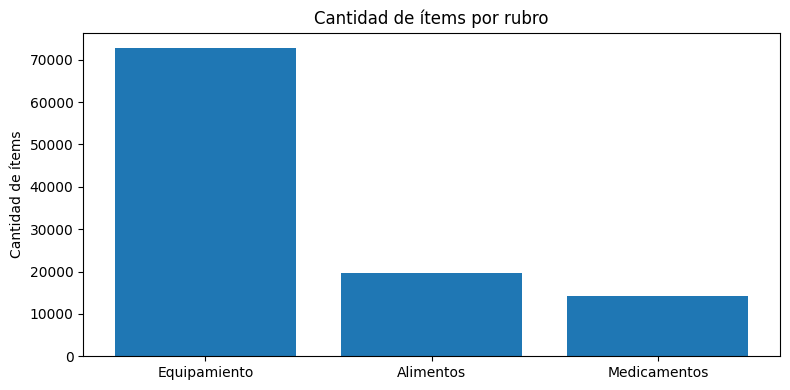

In [ ]:
# Separamos X (variables), y (target) y los grupos (la orden de cada fila)
X = df[FEATURES].copy()
y = df[TARGET].copy()
grupos = df["Codigo"].copy()

# Tabla y gráfico del desbalance
tabla_clases = y.value_counts().reindex(CLASES).rename_axis("Clase").reset_index(name="Ítems")
tabla_clases["Porcentaje"] = (100 * tabla_clases["Ítems"] / len(y)).round(2)
display(tabla_clases)

plt.figure(figsize=(8, 4))
plt.bar([CORTO[c] for c in tabla_clases["Clase"]], tabla_clases["Ítems"])
plt.ylabel("Cantidad de ítems")
plt.title("Cantidad de ítems por rubro")
plt.tight_layout()
plt.show()

## 2.1 Partición Train / Validation / Test por orden

Las líneas de una misma orden deben quedar en la misma partición. Si no, el modelo vería la orden en Train y se evaluaría con ella en Test. Por eso se usa GroupShuffleSplit con Codigo como grupo (semilla 42): 70% Train, 15% Validation y 15% Test.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
idx_train, idx_temp = next(gss.split(X, y, groups=grupos))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
i_val, i_test = next(gss2.split(X.iloc[idx_temp], y.iloc[idx_temp], groups=grupos.iloc[idx_temp]))

idx_val, idx_test = idx_temp[i_val], idx_temp[i_test]

X_train, y_train = X.iloc[idx_train].copy(), y.iloc[idx_train].copy()
X_val, y_val = X.iloc[idx_val].copy(), y.iloc[idx_val].copy()
X_test, y_test = X.iloc[idx_test].copy(), y.iloc[idx_test].copy()

In [ ]:
# Comprobación: ninguna orden puede estar en dos particiones
ord_train = set(grupos.iloc[idx_train])
ord_val = set(grupos.iloc[idx_val])
ord_test = set(grupos.iloc[idx_test])

print("Órdenes en Train y Validation:", len(ord_train & ord_val))
print("Órdenes en Train y Test:      ", len(ord_train & ord_test))
print("Órdenes en Validation y Test: ", len(ord_val & ord_test))

assert len(ord_train & ord_val) == 0 and len(ord_train & ord_test) == 0 and len(ord_val & ord_test) == 0
assert len(idx_train) + len(idx_val) + len(idx_test) == len(df)
print("\nTodo en orden: ninguna orden está repartida entre particiones.")

Órdenes en Train y Validation: 0
Órdenes en Train y Test:       0
Órdenes en Validation y Test:  0

Todo en orden: ninguna orden está repartida entre particiones.


In [ ]:
# Cuántas filas y órdenes tiene cada partición
tabla_particiones = pd.DataFrame({
    "Partición": ["Train", "Validation", "Test"],
    "Filas": [len(y_train), len(y_val), len(y_test)],
    "Órdenes": [len(ord_train), len(ord_val), len(ord_test)],
})
tabla_particiones["% de las filas"] = (100 * tabla_particiones["Filas"] / len(df)).round(1)
display(tabla_particiones)

# Cuántos ítems de cada clase hay en cada partición (soporte)
tabla_soporte = pd.DataFrame({
    "Train": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Test": y_test.value_counts(),
}).reindex(CLASES)
display(tabla_soporte)

display((100 * tabla_soporte / tabla_soporte.sum()).round(1).add_suffix(" (%)"))

,Partición,Filas,Órdenes,% de las filas
0,Train,74357,31018,69.8
1,Validation,16174,6647,15.2
2,Test,15991,6647,15.0


,Train,Validation,Test
RubroN1,,,
Equipamiento y suministros médicos,50992,11128,10584
"Alimentos, bebidas y tabaco",13406,2978,3165
Medicamentos y productos farmacéuticos,9959,2068,2242


,Train (%),Validation (%),Test (%)
RubroN1,,,
Equipamiento y suministros médicos,68.6,68.8,66.2
"Alimentos, bebidas y tabaco",18.0,18.4,19.8
Medicamentos y productos farmacéuticos,13.4,12.8,14.0


## 2.2 Análisis de la partición

La partición se hizo por orden usando Codigo, con semilla 42. La comprobación muestra cero órdenes repartidas entre particiones, así que el modelo nunca se evalúa con órdenes que vio al entrenar.

Como se reparten órdenes completas y no filas sueltas, los porcentajes por partición no son exactamente 70/15/15, y la proporción de cada clase cambia un poco de una partición a otra (se ve en la última tabla). Es normal: una orden grande con muchas líneas del mismo rubro mueve las cifras.

Lo que se aprende de los datos se calcula solo con Train (la mediana para SMOTENC y los pesos de clase). Validation sirve para elegir y Test queda guardado para el final.

# 3. Modelo por defecto y métodos para el desbalance

Se usa CatBoostClassifier con pérdida MultiClass, sin compensar las clases, con parada anticipada (early stopping) mirando Validation y use_best_model=True, que se queda con la mejor iteración.

Los hiperparámetros son los de referencia y son los mismos para todas las variantes, así la comparación mide solo el efecto del método:

In [ ]:
PARAMS = dict(
    loss_function="MultiClass",
    eval_metric="MultiClass",
    iterations=1500,       # máximo de árboles
    learning_rate=0.10,    # qué tan grande es cada paso
    depth=6,               # profundidad de cada árbol
    od_type="Iter",        # parar si deja de mejorar...
    od_wait=50,            # ...durante 50 iteraciones seguidas (paciencia)
    random_seed=42,
    task_type="GPU" if USAR_GPU else "CPU",
    verbose=100,
)
display(pd.Series(PARAMS, name="Valor").to_frame())

,Valor
loss_function,MultiClass
eval_metric,MultiClass
iterations,1500
learning_rate,0.1
depth,6
od_type,Iter
od_wait,50
random_seed,42
task_type,CPU
verbose,100


## 3.0 Funciones para entrenar

* crear_catboost arma el modelo con los parámetros de arriba.
* entrenar_o_cargar entrena el modelo, lo guarda en la carpeta modelos junto con sus curvas, y si ya existe guardado lo carga. Así no se pierde el trabajo si la sesión se corta.

In [ ]:
from catboost import CatBoostClassifier

def crear_catboost(class_weights=None):
    parametros = dict(PARAMS)
    if class_weights is not None:
        parametros["class_weights"] = class_weights
    return CatBoostClassifier(**parametros)


def entrenar_o_cargar(nombre, X_tr, y_tr, X_va, y_va, class_weights=None):
    ruta_modelo = CARPETA_MODELOS / f"{nombre}.cbm"
    ruta_historial = CARPETA_MODELOS / f"{nombre}_historial.json"
    modelo = crear_catboost(class_weights)

    if ruta_modelo.exists() and ruta_historial.exists() and not REENTRENAR:
        modelo.load_model(str(ruta_modelo))
        with open(ruta_historial) as f:
            historial = json.load(f)
        print(f"[{nombre}] cargado desde {ruta_modelo}")
    else:
        inicio = time.perf_counter()
        modelo.fit(X_tr, y_tr,
                   cat_features=CATEGORICAL_FEATURES,
                   eval_set=(X_va, y_va),
                   use_best_model=True)
        segundos = time.perf_counter() - inicio

        curvas = modelo.get_evals_result()
        historial = {
            "learn": curvas["learn"]["MultiClass"],
            "validation": curvas["validation"]["MultiClass"],
            "mejor_iteracion": int(modelo.get_best_iteration()),
            "segundos": segundos,
        }
        modelo.save_model(str(ruta_modelo))
        with open(ruta_historial, "w") as f:
            json.dump(historial, f)
        print(f"[{nombre}] entrenado en {segundos / 60:.1f} minutos")
    return modelo, historial


def resumen_entrenamiento(nombre, h):
    ejecutadas = len(h["validation"])
    se_paro_antes = ejecutadas < PARAMS["iterations"]
    return {
        "Modelo": nombre,
        "Mejor iteración": h["mejor_iteracion"],
        "Iteraciones ejecutadas": ejecutadas,
        "Máximo permitido": PARAMS["iterations"],
        "¿Qué pasó?": "Se activó la paciencia" if se_paro_antes else "Llegó al máximo de iteraciones",
        "Pérdida en Validation (mejor)": round(min(h["validation"]), 4),
    }

## 3.1 Modelo por defecto (sin compensar las clases)

In [ ]:
modelo_normal, hist_normal = entrenar_o_cargar("normal", X_train, y_train, X_val, y_val)

0:	learn: 0.9915232	test: 0.9923090	best: 0.9923090 (0)	total: 457ms	remaining: 11m 25s
100:	learn: 0.2852302	test: 0.2916448	best: 0.2916448 (100)	total: 41.7s	remaining: 9m 37s
200:	learn: 0.2562801	test: 0.2725775	best: 0.2725775 (200)	total: 1m 24s	remaining: 9m 6s
300:	learn: 0.2418870	test: 0.2653239	best: 0.2653239 (300)	total: 2m 7s	remaining: 8m 28s
400:	learn: 0.2314810	test: 0.2611369	best: 0.2611369 (400)	total: 2m 53s	remaining: 7m 55s
500:	learn: 0.2240635	test: 0.2576789	best: 0.2576045 (498)	total: 3m 38s	remaining: 7m 15s
600:	learn: 0.2167674	test: 0.2550138	best: 0.2550138 (600)	total: 4m 23s	remaining: 6m 34s
700:	learn: 0.2111474	test: 0.2533569	best: 0.2533464 (694)	total: 5m 8s	remaining: 5m 52s
800:	learn: 0.2064251	test: 0.2520613	best: 0.2519916 (794)	total: 5m 54s	remaining: 5m 9s
900:	learn: 0.2015861	test: 0.2512868	best: 0.2512868 (900)	total: 6m 40s	remaining: 4m 25s
1000:	learn: 0.1977231	test: 0.2504033	best: 0.2504033 (1000)	total: 7m 25s	remaining: 3m

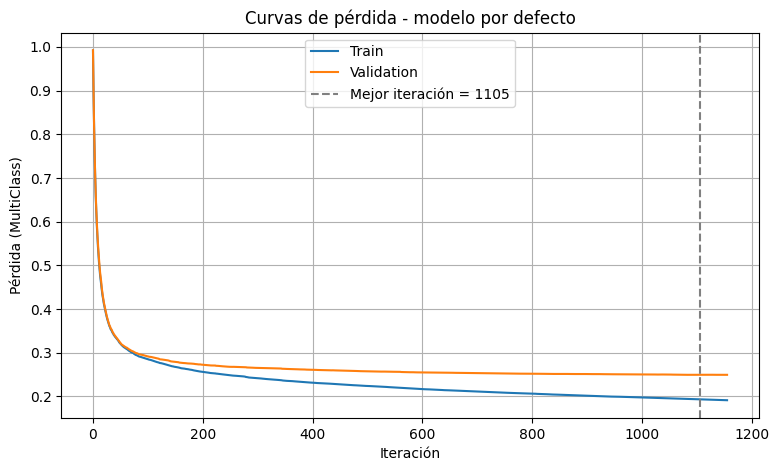

,Modelo,Mejor iteración,Iteraciones ejecutadas,Máximo permitido,¿Qué pasó?,Pérdida en Validation (mejor)
0,Normal,1105,1156,1500,Se activó la paciencia,0.2494


In [ ]:
# Curvas de pérdida reales de Train y Validation
mejor = hist_normal["mejor_iteracion"]

plt.figure(figsize=(9, 5))
plt.plot(hist_normal["learn"], label="Train")
plt.plot(hist_normal["validation"], label="Validation")
plt.axvline(mejor, color="gray", linestyle="--", label=f"Mejor iteración = {mejor}")
plt.xlabel("Iteración")
plt.ylabel("Pérdida (MultiClass)")
plt.title("Curvas de pérdida - modelo por defecto")
plt.legend()
plt.grid(True)
plt.show()

display(pd.DataFrame([resumen_entrenamiento("Normal", hist_normal)]))

### Análisis del entrenamiento

* La mejor iteración fue la 1105 y el modelo ejecutó 1156 iteraciones en total.
* El entrenamiento se detuvo por la paciencia: después de la iteración 1105 pasaron 50 iteraciones seguidas sin mejorar, así que el modelo paró solo y se quedó con la mejor versión. No llegó al máximo de 1500.
* En las curvas, la línea de Train baja más que la de Validation (al final, 0,19 contra 0,25). Es normal: el modelo conoce mejor los datos con los que aprendió. La línea de Validation baja muy despacio al final (casi plana), lo que indica que ya había aprendido casi todo lo que podía y que seguir entrenando daba muy poca mejora.
* Los otros dos modelos también pararon por paciencia (pesos de clase en la 911) salvo SMOTENC, que llegó al máximo de 1500 porque seguía mejorando muy de a poco.

Qué modelo se evalúa en Test: el modelo entrenado solo con Train (con la mejor iteración según Validation). No se vuelve a entrenar con Train + Validation.

## 3.2 Método A: pesos de clase

Los pesos se calculan solo con Train con la fórmula n / (k · n_c), donde n es el total de filas, k el número de clases y n_c las filas de cada clase. Las clases con menos ítems reciben más peso, para que sus errores "cuenten más" al entrenar.

In [ ]:
conteos_train = y_train.value_counts()
n_train = len(y_train)
k = len(conteos_train)

pesos_clase = {clase: n_train / (k * int(conteos_train[clase])) for clase in sorted(conteos_train.index)}
display(pd.Series(pesos_clase, name="Peso").round(4).to_frame())

,Peso
"Alimentos, bebidas y tabaco",1.8488
Equipamiento y suministros médicos,0.4861
Medicamentos y productos farmacéuticos,2.4888


In [ ]:
modelo_pesos, hist_pesos = entrenar_o_cargar("pesos_clase", X_train, y_train, X_val, y_val, class_weights=pesos_clase)

0:	learn: 0.9972613	test: 0.9986737	best: 0.9986737 (0)	total: 474ms	remaining: 11m 50s
100:	learn: 0.3497025	test: 0.3673152	best: 0.3673152 (100)	total: 42.2s	remaining: 9m 45s
200:	learn: 0.3078585	test: 0.3403543	best: 0.3403543 (200)	total: 1m 28s	remaining: 9m 30s
300:	learn: 0.2878801	test: 0.3299143	best: 0.3299143 (300)	total: 2m 14s	remaining: 8m 53s
400:	learn: 0.2721455	test: 0.3235490	best: 0.3235490 (400)	total: 2m 59s	remaining: 8m 12s
500:	learn: 0.2610805	test: 0.3201131	best: 0.3200242 (497)	total: 3m 45s	remaining: 7m 29s
600:	learn: 0.2518440	test: 0.3176502	best: 0.3176151 (599)	total: 4m 31s	remaining: 6m 46s
700:	learn: 0.2439616	test: 0.3161477	best: 0.3160751 (697)	total: 5m 18s	remaining: 6m 2s
800:	learn: 0.2360456	test: 0.3148074	best: 0.3147007 (790)	total: 6m 4s	remaining: 5m 17s
900:	learn: 0.2283364	test: 0.3134172	best: 0.3134172 (900)	total: 6m 49s	remaining: 4m 32s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.3133664154
bestIter

## 3.3 Método B: SMOTENC

SMOTENC crea ítems sintéticos de las clases chicas a partir de ítems parecidos. Reglas que se cumplen aquí:

* Se aplica solo sobre Train. Validation y Test no se tocan.
* SMOTENC no acepta datos faltantes, así que antes se rellenan los números con la mediana de Train. Los mismos valores se usan después en Validation y Test.
* SMOTENC necesita las categorías como números, así que se codifican con un OrdinalEncoder ajustado solo con Train. Después de crear los datos sintéticos se devuelven a texto, para que CatBoost use las mismas columnas que en los otros modelos.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from imblearn.over_sampling import SMOTENC

# 1) Rellenar números que faltan con la mediana de Train
imputador = SimpleImputer(strategy="median")
X_train_i = X_train.copy()
X_val_i = X_val.copy()
X_test_i = X_test.copy()

X_train_i[NUMERIC_FEATURES] = imputador.fit_transform(X_train[NUMERIC_FEATURES])
X_val_i[NUMERIC_FEATURES] = imputador.transform(X_val[NUMERIC_FEATURES])
X_test_i[NUMERIC_FEATURES] = imputador.transform(X_test[NUMERIC_FEATURES])

# 2) Pasar las categorías a números (solo para SMOTENC)
codificador = OrdinalEncoder()
X_train_num = X_train_i.copy()
X_train_num[CATEGORICAL_FEATURES] = codificador.fit_transform(X_train_i[CATEGORICAL_FEATURES])

# 3) Crear los datos sintéticos (solo en Train)
posiciones_cat = [X_train_num.columns.get_loc(c) for c in CATEGORICAL_FEATURES]
smote = SMOTENC(categorical_features=posiciones_cat, random_state=SEMILLA)
X_res, y_res = smote.fit_resample(X_train_num, y_train)

# 4) Devolver las categorías a texto
X_res = pd.DataFrame(X_res, columns=FEATURES)
codigos = np.rint(X_res[CATEGORICAL_FEATURES].astype(float)).astype(int)
X_res[CATEGORICAL_FEATURES] = codificador.inverse_transform(codigos)
X_res[NUMERIC_FEATURES] = X_res[NUMERIC_FEATURES].astype(float)
y_res = pd.Series(np.asarray(y_res).astype(str), name=TARGET)

X_train_smote, y_train_smote = X_res, y_res

print("Train original:      ", X_train.shape)
print("Train con SMOTENC:   ", X_train_smote.shape)
display(pd.DataFrame({"Antes": y_train.value_counts(), "Después": y_train_smote.value_counts()}).reindex(CLASES))

Train original:       (74357, 11)
Train con SMOTENC:    (152976, 11)


,Antes,Después
RubroN1,,
Equipamiento y suministros médicos,50992,50992
"Alimentos, bebidas y tabaco",13406,50992
Medicamentos y productos farmacéuticos,9959,50992


In [ ]:
# Validation y Test se usan SIN sobremuestreo (solo con los números rellenados con la mediana de Train)
modelo_smote, hist_smote = entrenar_o_cargar("smotenc", X_train_smote, y_train_smote, X_val_i, y_val)

0:	learn: 0.9927562	test: 1.0059925	best: 1.0059925 (0)	total: 770ms	remaining: 19m 13s
100:	learn: 0.3032155	test: 0.3791436	best: 0.3791436 (100)	total: 1m 23s	remaining: 19m 22s
200:	learn: 0.2541645	test: 0.3410477	best: 0.3410477 (200)	total: 2m 55s	remaining: 18m 57s
300:	learn: 0.2289504	test: 0.3229344	best: 0.3229344 (300)	total: 4m 24s	remaining: 17m 33s
400:	learn: 0.2130506	test: 0.3117246	best: 0.3117246 (400)	total: 5m 51s	remaining: 16m 2s
500:	learn: 0.2010609	test: 0.3041156	best: 0.3041156 (500)	total: 7m 18s	remaining: 14m 33s
600:	learn: 0.1920769	test: 0.2992018	best: 0.2992018 (600)	total: 8m 45s	remaining: 13m 5s
700:	learn: 0.1838100	test: 0.2959154	best: 0.2958984 (693)	total: 10m 12s	remaining: 11m 38s
800:	learn: 0.1778614	test: 0.2930923	best: 0.2930412 (797)	total: 11m 42s	remaining: 10m 12s
900:	learn: 0.1724581	test: 0.2904102	best: 0.2903371 (893)	total: 13m 15s	remaining: 8m 48s
1000:	learn: 0.1676774	test: 0.2884161	best: 0.2884161 (1000)	total: 14m 41

## 3.4 Método C: ajuste del umbral

Se usan las probabilidades del modelo por defecto sobre Validation. La regla es:

* si P(Medicamentos) ≥ t, se predice Medicamentos;
* si no, se predice la más probable entre las otras dos clases.

Se prueban muchos valores de t y se elige el que da el mayor F1 macro en Validation.

In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

def predecir_con_umbral(probabilidades, clases, umbral, clase_interes=CLASE_INTERES):
    clases = np.array(clases)
    i = list(clases).index(clase_interes)
    otras = [j for j in range(len(clases)) if j != i]
    mejor_otra = clases[otras][np.argmax(probabilidades[:, otras], axis=1)]
    return np.where(probabilidades[:, i] >= umbral, clase_interes, mejor_otra)


prob_val_normal = modelo_normal.predict_proba(X_val)
print("Orden de las clases en las probabilidades:", list(modelo_normal.classes_))

indice_med = list(modelo_normal.classes_).index(CLASE_INTERES)
umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)

filas = []
for t in umbrales:
    pred = predecir_con_umbral(prob_val_normal, modelo_normal.classes_, t)
    p, r, f, _ = precision_recall_fscore_support(y_val, pred, labels=[CLASE_INTERES], zero_division=0)
    filas.append({"Umbral": t,
                  "F1 macro": f1_score(y_val, pred, average="macro"),
                  "Recall Medicamentos": r[0],
                  "Precisión Medicamentos": p[0]})

tabla_umbral = pd.DataFrame(filas)
mejor_umbral = float(tabla_umbral.loc[tabla_umbral["F1 macro"].idxmax(), "Umbral"])
print(f"\nMejor umbral según F1 macro en Validation: {mejor_umbral:.2f}")
display(tabla_umbral.loc[tabla_umbral["Umbral"] == mejor_umbral].round(4))

Orden de las clases en las probabilidades: ['Alimentos, bebidas y tabaco', 'Equipamiento y suministros médicos', 'Medicamentos y productos farmacéuticos']

Mejor umbral según F1 macro en Validation: 0.32


,Umbral,F1 macro,Recall Medicamentos,Precisión Medicamentos
27,0.32,0.8667,0.7379,0.8027


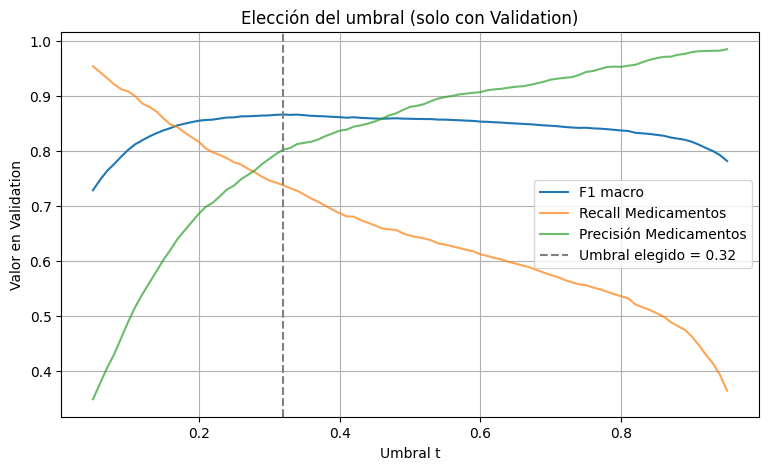

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(tabla_umbral["Umbral"], tabla_umbral["F1 macro"], label="F1 macro")
plt.plot(tabla_umbral["Umbral"], tabla_umbral["Recall Medicamentos"], label="Recall Medicamentos", alpha=0.7)
plt.plot(tabla_umbral["Umbral"], tabla_umbral["Precisión Medicamentos"], label="Precisión Medicamentos", alpha=0.7)
plt.axvline(mejor_umbral, color="gray", linestyle="--", label=f"Umbral elegido = {mejor_umbral:.2f}")
plt.xlabel("Umbral t")
plt.ylabel("Valor en Validation")
plt.title("Elección del umbral (solo con Validation)")
plt.legend()
plt.grid(True)
plt.show()

## 3.5 Resumen del entrenamiento de los tres modelos

In [ ]:
resumen = pd.DataFrame([
    resumen_entrenamiento("Normal", hist_normal),
    resumen_entrenamiento("Pesos de clase", hist_pesos),
    resumen_entrenamiento("SMOTENC", hist_smote),
])
display(resumen)

,Modelo,Mejor iteración,Iteraciones ejecutadas,Máximo permitido,¿Qué pasó?,Pérdida en Validation (mejor)
0,Normal,1105,1156,1500,Se activó la paciencia,0.2494
1,Pesos de clase,911,962,1500,Se activó la paciencia,0.3134
2,SMOTENC,1499,1500,1500,Llegó al máximo de iteraciones,0.2831


Las pérdidas de modelos distintos no se comparan entre sí: con pesos de clase el modelo mide el error de otra forma, y SMOTENC entrena con más filas. Las curvas solo sirven para ver en qué iteración conviene parar cada modelo. La comparación entre métodos se hace en la sección siguiente con métricas sobre Validation.

## 3.6 Comparación en Validation

Se comparan las cuatro variantes con las mismas filas de Validation: accuracy, F1 macro, F1 weighted y recall, precisión y F1 de cada clase. (La precisión se agrega para poder ver cuánto cuesta subir el recall.)

In [ ]:
# Predicciones en Validation de las cuatro variantes
pred_val = {
    "Normal": modelo_normal.predict(X_val).ravel(),
    "Pesos de clase": modelo_pesos.predict(X_val).ravel(),
    "SMOTENC": modelo_smote.predict(X_val_i).ravel(),
    "Umbral": predecir_con_umbral(prob_val_normal, modelo_normal.classes_, mejor_umbral),
}


def calcular_metricas(nombre, y_real, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_real, y_pred, labels=CLASES, zero_division=0)
    fila = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "F1 macro": f1_score(y_real, y_pred, labels=CLASES, average="macro", zero_division=0),
        "F1 weighted": f1_score(y_real, y_pred, labels=CLASES, average="weighted", zero_division=0),
    }
    for i, clase in enumerate(CLASES):
        fila[f"Recall {CORTO[clase]}"] = recall[i]
    for i, clase in enumerate(CLASES):
        fila[f"F1 {CORTO[clase]}"] = f1[i]
    for i, clase in enumerate(CLASES):
        fila[f"Precisión {CORTO[clase]}"] = precision[i]
    return fila


tabla_val = pd.DataFrame([calcular_metricas(n, y_val, p) for n, p in pred_val.items()]).set_index("Modelo")
display(tabla_val.T.round(4))

Modelo,Normal,Pesos de clase,SMOTENC,Umbral
Accuracy,0.9087,0.8761,0.8979,0.9090
F1 macro,0.8591,0.8357,0.8554,0.8667
F1 weighted,0.9053,0.8803,0.8984,0.9079
Recall Equipamiento,0.9680,0.8720,0.9220,0.9523
Recall Alimentos,0.8664,0.9241,0.9040,0.8660
Recall Medicamentos,0.6504,0.8288,0.7597,0.7379
F1 Equipamiento,0.9381,0.9109,0.9287,0.9375
F1 Alimentos,0.8937,0.8792,0.8899,0.8936
F1 Medicamentos,0.7456,0.7170,0.7476,0.7690
Precisión Equipamiento,0.9100,0.9533,0.9355,0.9232


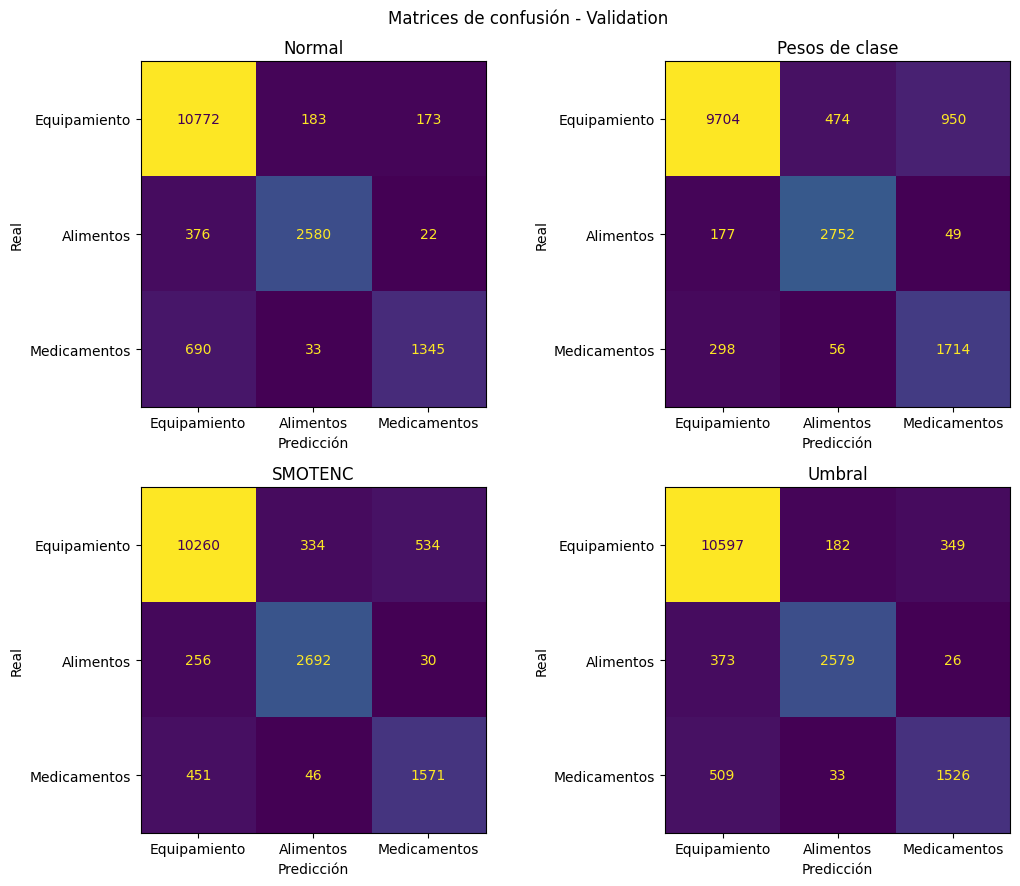

In [ ]:
def graficar_matrices(y_real, predicciones, titulo):
    fig, ejes = plt.subplots(2, 2, figsize=(11, 9))
    for eje, (nombre, pred) in zip(ejes.ravel(), predicciones.items()):
        cm = confusion_matrix(y_real, pred, labels=CLASES)
        ConfusionMatrixDisplay(cm, display_labels=[CORTO[c] for c in CLASES]).plot(
            ax=eje, colorbar=False, values_format="d")
        eje.set_title(nombre)
        eje.set_xlabel("Predicción")
        eje.set_ylabel("Real")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

graficar_matrices(y_val, pred_val, "Matrices de confusión - Validation")

In [ ]:
# Qué cambió cada método respecto al modelo por defecto (en Validation)
base = tabla_val.loc["Normal"]
cambios = pd.DataFrame({
    metodo: {
        "Cambio F1 macro": tabla_val.loc[metodo, "F1 macro"] - base["F1 macro"],
        "Cambio recall Medicamentos": tabla_val.loc[metodo, "Recall Medicamentos"] - base["Recall Medicamentos"],
        "Cambio precisión Medicamentos": tabla_val.loc[metodo, "Precisión Medicamentos"] - base["Precisión Medicamentos"],
        "Cambio recall Equipamiento (mayoritaria)": tabla_val.loc[metodo, "Recall Equipamiento"] - base["Recall Equipamiento"],
        "Cambio recall Alimentos": tabla_val.loc[metodo, "Recall Alimentos"] - base["Recall Alimentos"],
    }
    for metodo in ["Pesos de clase", "SMOTENC", "Umbral"]
}).T
display(cambios.round(4))

# Elección del modelo final: el de mayor F1 macro en Validation
nombre_final = tabla_val["F1 macro"].idxmax()
print(f"\nMODELO ELEGIDO (mayor F1 macro en Validation): {nombre_final}")
print(f"F1 macro en Validation: {tabla_val.loc[nombre_final, 'F1 macro']:.4f}  (modelo normal: {base['F1 macro']:.4f})")

mas_recall = cambios["Cambio recall Medicamentos"].idxmax()
print(f"El método que más subió el recall de Medicamentos: {mas_recall} ({cambios.loc[mas_recall, 'Cambio recall Medicamentos']:+.4f})")

,Cambio F1 macro,Cambio recall Medicamentos,Cambio precisión Medicamentos,Cambio recall Equipamiento (mayoritaria),Cambio recall Alimentos
Pesos de clase,-0.0234,0.1784,-0.2416,-0.0960,0.0578
SMOTENC,-0.0037,0.1093,-0.1375,-0.0460,0.0376
Umbral,0.0076,0.0875,-0.0706,-0.0157,-0.0003



MODELO ELEGIDO (mayor F1 macro en Validation): Umbral
F1 macro en Validation: 0.8667  (modelo normal: 0.8591)
El método que más subió el recall de Medicamentos: Pesos de clase (+0.1784)


### Análisis de Validation

Esta elección ya no se cambia después de ver Test.

Palabras que se usan: recall es "de todos los ítems que de verdad eran de una clase, cuántos encontró el modelo". Precisión es "de todos los que el modelo dijo que eran de una clase, cuántos de verdad lo eran".

1. Qué modelo ganó. Ganó el método del umbral (con umbral 0,32), con un F1 macro de 0,8667. El modelo normal sacó 0,8591, así que la ganancia fue pequeña (+0,0076). Los pesos de clase (0,8357) y SMOTENC (0,8554) quedaron por debajo del modelo normal. O sea, solo el umbral logró mejorarlo, y por poco.

2. Qué ganó y qué perdió cada clase. Todos los métodos hacen lo mismo: encuentran más Medicamentos, pero a cambio se equivocan más.

| Método | Recall de Medicamentos | Precisión de Medicamentos | Recall de Equipamiento (la clase más grande) |
|---|---|---|---|
| Normal | 0,650 | 0,873 | 0,968 |
| Pesos de clase | 0,829 (+0,178) | 0,632 (−0,242) | 0,872 (−0,096) |
| SMOTENC | 0,760 (+0,109) | 0,736 (−0,138) | 0,922 (−0,046) |
| Umbral | 0,738 (+0,088) | 0,803 (−0,071) | 0,952 (−0,016) |

* Medicamentos es la clase que más mejora en recall en los tres métodos, pero baja la precisión: se empiezan a marcar como Medicamentos cosas que no lo son. Con los pesos de clase la precisión baja mucho (0,87 a 0,63), por eso su F1 macro empeora.
* Equipamiento (la clase más grande) es la que paga el costo: pierde aciertos porque algunos de sus ítems pasan a Medicamentos. Con el umbral pierde muy poco (−0,016) y con los pesos pierde bastante (−0,096).
* Alimentos también sube su recall con los pesos de clase (+0,058) y con SMOTENC (+0,038), pero con una caída de precisión (de 0,92 a 0,84 y 0,88). Con el umbral queda casi igual, porque ese método solo mueve la clase Medicamentos.

3. Por qué el umbral ganó. Mueve solo un poco la decisión para una clase, así que gana algo de recall sin perder tanto en las demás. Los pesos y SMOTENC cambian todo el aprendizaje del modelo y cuestan más.

## 3.7 Comparación de los tres métodos (bonificación)

* Pesos de clase: el modelo se entrena dándole más importancia a los errores en las clases chicas. No cambia los datos, pero hay que volver a entrenar.
* SMOTENC: se agregan ítems sintéticos de las clases chicas en Train. Sirve cuando faltan ejemplos de las clases chicas, pero triplica el tamaño de Train (entrenar demora más) y sus ítems nuevos se construyen mezclando ítems reales; como compara por distancia, los montos (que son números enormes) pesan mucho en esa comparación.
* Ajuste del umbral: no se vuelve a entrenar nada; solo se cambia la regla de decisión para una clase. Es lo más barato y rápido, y sirve cuando importa especialmente detectar una clase (aquí Medicamentos). Solo mueve esa clase.

Cuál prefiero según la situación: los pesos de clase cuando quiero que el modelo aprenda todas las clases con cuidado y puedo reentrenar, SMOTENC cuando una clase tiene muy pocos ejemplos, el umbral cuando el modelo ya está entrenado y solo quiero decidir cuánto me importa no dejar pasar una clase concreta.

Las cifras de cuál método movió más el recall de Medicamentos y cuánto costó en precisión y en la clase mayoritaria están en la tabla de cambios de la sección 3.6. Resumen con las cifras reales de Validation:

* Método que más subió el recall de Medicamentos: los pesos de clase, de 0,650 a 0,829 (+0,178). Le siguen SMOTENC (+0,109) y el umbral (+0,088).
* Lo que costó en precisión de Medicamentos: los pesos de clase la bajaron de 0,873 a 0,632 (−0,242), SMOTENC a 0,736 (−0,138) y el umbral a 0,803 (−0,071). Mientras más recall se gana, más precisión se pierde.
* Lo que costó en la clase más grande (Equipamiento): el recall bajó −0,096 con los pesos de clase, −0,046 con SMOTENC y −0,016 con el umbral.
* El mejor equilibrio lo dio el umbral: subió menos el recall, pero fue el que menos perdió en lo demás y el único que mejoró el F1 macro.

# 4. Evaluación en Test y auditoría

La elección del modelo ya está cerrada (sección 3.6). Ahora se evalúa una sola vez en Test, sin cambiar nada de lo anterior. Se reportan las cuatro variantes.

In [ ]:
prob_test_normal = modelo_normal.predict_proba(X_test)

pred_test = {
    "Normal": modelo_normal.predict(X_test).ravel(),
    "Pesos de clase": modelo_pesos.predict(X_test).ravel(),
    "SMOTENC": modelo_smote.predict(X_test_i).ravel(),
    "Umbral": predecir_con_umbral(prob_test_normal, modelo_normal.classes_, mejor_umbral),
}

tabla_test = pd.DataFrame([calcular_metricas(n, y_test, p) for n, p in pred_test.items()]).set_index("Modelo")
display(tabla_test.T.round(4))
print(f"Modelo elegido en Validation: {nombre_final}")

Modelo,Normal,Pesos de clase,SMOTENC,Umbral
Accuracy,0.9028,0.8601,0.8843,0.8993
F1 macro,0.8579,0.8225,0.8418,0.8579
F1 weighted,0.8993,0.8650,0.8845,0.8980
Recall Equipamiento,0.9626,0.8536,0.9126,0.9443
Recall Alimentos,0.8840,0.9229,0.9062,0.8837
Recall Medicamentos,0.6472,0.8024,0.7199,0.7087
F1 Equipamiento,0.9325,0.8977,0.9184,0.9300
F1 Alimentos,0.9016,0.8802,0.8894,0.9015
F1 Medicamentos,0.7396,0.6897,0.7175,0.7420
Precisión Equipamiento,0.9042,0.9466,0.9243,0.9161


Modelo elegido en Validation: Umbral


In [ ]:
# Informe por clase (con soporte) de cada variante
for nombre, pred in pred_test.items():
    marca = "   <-- MODELO ELEGIDO" if nombre == nombre_final else ""
    print("=" * 70)
    print(f"{nombre.upper()}{marca}")
    print(classification_report(y_test, pred, labels=CLASES, digits=3, zero_division=0))

NORMAL
                                        precision    recall  f1-score   support

    Equipamiento y suministros médicos      0.904     0.963     0.932     10584
           Alimentos, bebidas y tabaco      0.920     0.884     0.902      3165
Medicamentos y productos farmacéuticos      0.863     0.647     0.740      2242

                              accuracy                          0.903     15991
                             macro avg      0.896     0.831     0.858     15991
                          weighted avg      0.901     0.903     0.899     15991

PESOS DE CLASE
                                        precision    recall  f1-score   support

    Equipamiento y suministros médicos      0.947     0.854     0.898     10584
           Alimentos, bebidas y tabaco      0.841     0.923     0.880      3165
Medicamentos y productos farmacéuticos      0.605     0.802     0.690      2242

                              accuracy                          0.860     15991
             

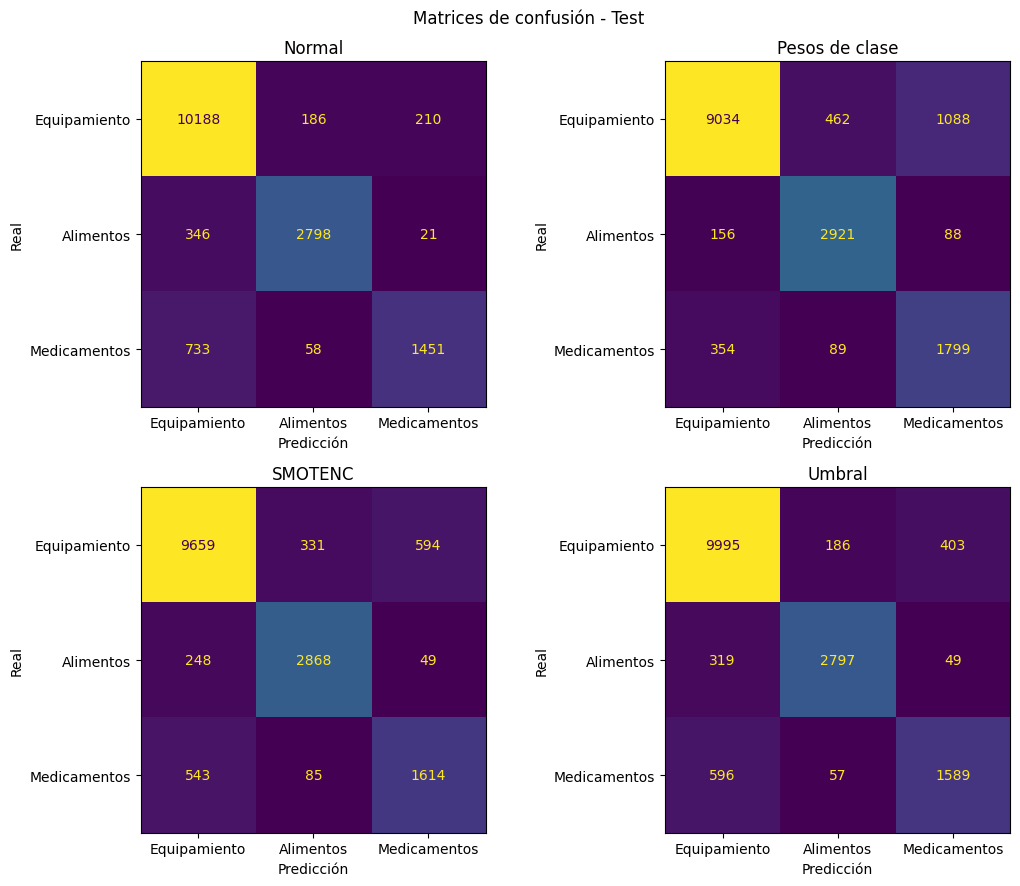

In [ ]:
graficar_matrices(y_test, pred_test, "Matrices de confusión - Test")

## 4.1 Confusiones y clase con peor resultado

In [ ]:
pred_elegido = pred_test[nombre_final]
cm = confusion_matrix(y_test, pred_elegido, labels=CLASES)

filas = []
for i, real in enumerate(CLASES):
    for j, predicha in enumerate(CLASES):
        if i != j:
            filas.append({"Real": CORTO[real], "Predicho": CORTO[predicha], "Casos": int(cm[i, j]),
                          "% de la clase real": round(100 * cm[i, j] / cm[i].sum(), 1)})
confusiones = pd.DataFrame(filas).sort_values("Casos", ascending=False).reset_index(drop=True)
print(f"Confusiones del modelo elegido ({nombre_final}) en Test:")
display(confusiones)

reporte = classification_report(y_test, pred_elegido, labels=CLASES, output_dict=True, zero_division=0)
peor = min(CLASES, key=lambda c: reporte[c]["f1-score"])
print(f"Clase con peor resultado: {CORTO[peor]}  (F1 = {reporte[peor]['f1-score']:.3f}, "
      f"recall = {reporte[peor]['recall']:.3f}, precisión = {reporte[peor]['precision']:.3f})")

Confusiones del modelo elegido (Umbral) en Test:


,Real,Predicho,Casos,% de la clase real
0,Medicamentos,Equipamiento,596,26.6
1,Equipamiento,Medicamentos,403,3.8
2,Alimentos,Equipamiento,319,10.1
3,Equipamiento,Alimentos,186,1.8
4,Medicamentos,Alimentos,57,2.5
5,Alimentos,Medicamentos,49,1.5


Clase con peor resultado: Medicamentos  (F1 = 0.742, recall = 0.709, precisión = 0.779)


### Análisis de Test

1. Resultado del modelo elegido (umbral 0,32). En Test sacó accuracy 0,8993, F1 macro 0,8579 y F1 weighted 0,8980. En Validation el F1 macro había sido 0,8667, o sea bajó un poco (−0,009). Es normal que Test salga algo más bajo, porque Test no se usó para elegir nada.

2. Dos confusiones concretas.

* Medicamentos clasificados como Equipamiento: 596 casos (26,6% de todos los Medicamentos). Es el error más grande. Una posible razón: el modelo no lee la descripción del producto, solo ve datos como la unidad de medida, la región, los montos y la cantidad. Medicamentos y equipos médicos los compran los mismos hospitales, en las mismas regiones, y muchas veces en "unidades" y con precios parecidos. Para el modelo se parecen.
* Alimentos clasificados como Equipamiento: 319 casos (10,1% de los Alimentos). Pasa algo parecido: los alimentos de uso hospitalario (leches, suplementos, colaciones) se compran de forma muy parecida a los suministros médicos.
* También se ve el camino contrario: 403 ítems de Equipamiento se marcaron como Medicamentos (solo 3,8% de Equipamiento, pero como esta clase es enorme, son bastantes casos).

3. Clase con peor resultado: Medicamentos (F1 0,742, recall 0,709, precisión 0,779). Es la más difícil porque tiene pocos ejemplos (es la más pequeña) y porque se parece mucho a Equipamiento para el modelo.

4. Comparación con el modelo normal en Test. Los dos quedaron empatados en F1 macro (0,8579). El umbral encuentra más Medicamentos (recall 0,647 a 0,709) pero se equivoca más al marcarlos (precisión 0,863 a 0,779), y el accuracy bajó un poco (0,9028 a 0,8993). O sea, la ventaja pequeña que se vio en Validation no se mantuvo en Test. Los pesos de clase (0,8225) y SMOTENC (0,8418) siguieron quedando por debajo. La elección hecha en Validation no se cambió.

## 4.2 Importancia de variables del modelo elegido

,Variable,Importancia
0,RegionUnidadCompra,15.05
1,precioNeto,13.79
2,UnidadMedida,13.69
3,MontoTotalOC_PesosChilenos,12.27
4,RegionProveedor,11.49
5,sector,9.59
6,cantidad,8.71
7,totalLineaNeto,8.00
8,Tipo,6.45
9,TipoImpuesto,0.51


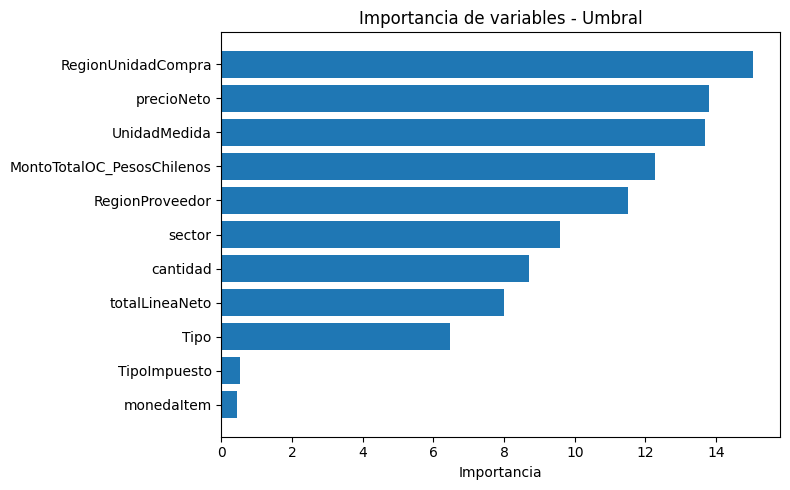

In [ ]:
modelos_por_nombre = {"Normal": modelo_normal, "Pesos de clase": modelo_pesos,
                      "SMOTENC": modelo_smote, "Umbral": modelo_normal}   # el umbral usa el modelo normal
modelo_final = modelos_por_nombre[nombre_final]

tabla_importancia = pd.DataFrame({
    "Variable": modelo_final.feature_names_,
    "Importancia": modelo_final.get_feature_importance(),
}).sort_values("Importancia", ascending=False).reset_index(drop=True)
display(tabla_importancia.round(2))

plt.figure(figsize=(8, 5))
orden = tabla_importancia.sort_values("Importancia")
plt.barh(orden["Variable"], orden["Importancia"])
plt.xlabel("Importancia")
plt.title(f"Importancia de variables - {nombre_final}")
plt.tight_layout()
plt.show()

### Análisis de la importancia

Las variables más importantes fueron:

1. RegionUnidadCompra (15,05)
2. precioNeto (13,79)
3. UnidadMedida (13,69)
4. MontoTotalOC_PesosChilenos (12,27)
5. RegionProveedor (11,49)

Las que casi no aportan son TipoImpuesto (0,51) y monedaItem (0,43).

¿Tienen sentido? En general sí:

* UnidadMedida tiene sentido: los alimentos suelen comprarse en kilos, litros o cajas, y los equipos en unidades.
* precioNeto y MontoTotalOC tienen sentido: un medicamento, un alimento y un equipo médico suelen tener precios y tamaños de compra distintos.
* RegionUnidadCompra y RegionProveedor sorprenden un poco. Una posible explicación es que cada región o cada comprador compra siempre el mismo tipo de cosas, y entonces la región ayuda a "adivinar" el rubro. Esto es una pista, no una prueba.
* TipoImpuesto y monedaItem casi no importan, lo que es lógico: casi todas las compras son en pesos y con el mismo impuesto, así que no ayudan a separar los rubros.

La importancia de las variables está bastante repartida: ninguna domina sola. Esto coincide con que el modelo acierta bastante, pero no es perfecto.

Importante: importancia no es causalidad. Que una variable pese mucho solo significa que el modelo la usa para decidir. No significa que la región o el precio hagan que un ítem sea de cierto rubro.

## 4.3 Revisión de cinco errores

Se toman 5 errores al azar (semilla fija) del modelo elegido en Test y se muestra el texto que escribió el comprador (EspecificacionComprador), que no entra al modelo y sirve solo para revisar.

In [ ]:
df_test = df.iloc[idx_test].copy()
df_test["Real"] = y_test.values
df_test["Predicho"] = pred_elegido

errores = df_test[df_test["Real"] != df_test["Predicho"]]
print(f"Errores del modelo elegido en Test: {len(errores):,} de {len(df_test):,} ítems ({100 * len(errores) / len(df_test):.1f}%)\n")

muestra = errores.sample(5, random_state=SEMILLA)
for n, (_, fila) in enumerate(muestra.iterrows(), start=1):
    texto = str(fila["EspecificacionComprador"])
    print(f"--- Error {n} ---")
    print(f"Orden: {fila['Codigo']}   Ítem: {fila['IDItem']}")
    print(f"Real: {fila['Real']}")
    print(f"Predicho: {fila['Predicho']}")
    print("Especificación:", textwrap.shorten(texto, width=500, placeholder=" [...]"))
    print()

Errores del modelo elegido en Test: 1,610 de 15,991 ítems (10.1%)

--- Error 1 ---
Orden: 1057506-2553-SE25   Ítem: 146547869
Real: Alimentos, bebidas y tabaco
Predicho: Equipamiento y suministros médicos
Especificación: Fruta y verduras DICIEMBRE 2025

--- Error 2 ---
Orden: 2196-5-SE26   Ítem: 146472067
Real: Alimentos, bebidas y tabaco
Predicho: Equipamiento y suministros médicos
Especificación: POSTRE ENVASADO DE LECHE SIN LACTOSA TIPO LECHE ASADA, CHANDELLE O PANACOTA DIFERENTES SABORES, FORMATO INDIVIDUAL

--- Error 3 ---
Orden: 2196-78-SE26   Ítem: 146627840
Real: Alimentos, bebidas y tabaco
Predicho: Equipamiento y suministros médicos
Especificación: NESTUM 5 CEREALES CAJAS DE 350 GRS NETO

--- Error 4 ---
Orden: 1057480-280-SE26   Ítem: 146845259
Real: Alimentos, bebidas y tabaco
Predicho: Equipamiento y suministros médicos
Especificación: PEDIASURE 850GRS

--- Error 5 ---
Orden: 2153-7-AG26   Ítem: 146495105
Real: Alimentos, bebidas y tabaco
Predicho: Equipamiento y suministr

### Comentario de los 5 errores

Los cinco errores revisados son Alimentos que el modelo marcó como Equipamiento, que es una de las confusiones más grandes de la matriz (319 casos).

* Error 1 (Fruta y verduras DICIEMBRE 2025): el texto deja claro que es comida. Parece un error del modelo: el modelo no lee el texto y por eso no se da cuenta.
* Error 2 (postre de leche sin lactosa): es un alimento claro. Error del modelo.
* Error 3 (Nestum 5 cereales): es un alimento claro. Error del modelo.
* Error 4 (Pediasure 850 grs): es una fórmula nutricional que se usa en hospitales. Puede considerarse alimento o producto médico, así que la etiqueta es discutible. Aquí el modelo se pudo equivocar con razón.
* Error 5 (agua mineral sin gas Cachantún): es una bebida clara. Error del modelo. Es probable que el pedido venga de un hospital, que normalmente compra insumos médicos.

En resumen: 4 de 5 parecen errores del modelo y 1 parece una etiqueta discutible. Casi todos tienen en común que el texto dice claramente qué es, pero el modelo no usa el texto. Una mejora futura sería agregar la descripción como variable. Como son solo 5 casos al azar y del mismo tipo, no sirven para opinar sobre las otras confusiones.

# 5. Conclusión y reproducibilidad

In [ ]:
# Resumen automático con las cifras reales (para usar en la conclusión)
b_val, f_val = tabla_val.loc["Normal"], tabla_val.loc[nombre_final]
b_test, f_test = tabla_test.loc["Normal"], tabla_test.loc[nombre_final]

print(f"Modelo elegido en Validation: {nombre_final}")
print(f"  F1 macro Validation: {f_val['F1 macro']:.4f} (normal: {b_val['F1 macro']:.4f})")
print(f"  F1 macro Test:       {f_test['F1 macro']:.4f} (normal: {b_test['F1 macro']:.4f})")
print(f"  Accuracy Test:       {f_test['Accuracy']:.4f} (normal: {b_test['Accuracy']:.4f})")
print(f"  Recall Medicamentos Validation: {b_val['Recall Medicamentos']:.4f} -> {f_val['Recall Medicamentos']:.4f}")
print(f"  Recall Medicamentos Test:       {b_test['Recall Medicamentos']:.4f} -> {f_test['Recall Medicamentos']:.4f}")
print(f"  Precisión Medicamentos Test:    {b_test['Precisión Medicamentos']:.4f} -> {f_test['Precisión Medicamentos']:.4f}")
print(f"  Recall Equipamiento Test:       {b_test['Recall Equipamiento']:.4f} -> {f_test['Recall Equipamiento']:.4f}")
print(f"Se evaluó en Test el modelo entrenado solo con Train. Equipo de cálculo: {'GPU' if USAR_GPU else 'CPU'}.")

Modelo elegido en Validation: Umbral
  F1 macro Validation: 0.8667 (normal: 0.8591)
  F1 macro Test:       0.8579 (normal: 0.8579)
  Accuracy Test:       0.8993 (normal: 0.9028)
  Recall Medicamentos Validation: 0.6504 -> 0.7379
  Recall Medicamentos Test:       0.6472 -> 0.7087
  Precisión Medicamentos Test:    0.8627 -> 0.7785
  Recall Equipamiento Test:       0.9626 -> 0.9443
Se evaluó en Test el modelo entrenado solo con Train. Equipo de cálculo: CPU.


## 5.1 Conclusión

Qué modelo elegí y por qué. Elegí el modelo con ajuste de umbral (0,32) porque tuvo el mayor F1 macro en Validation (0,8667, contra 0,8591 del modelo normal). Usé el F1 macro porque da el mismo peso a las tres clases, y el accuracy podría engañar, ya que Equipamiento es casi el 70% de los datos.

Qué cambió el método de desbalance. El umbral subió el recall de Medicamentos (de 0,647 a 0,709 en Test), pero bajó la precisión (de 0,863 a 0,779) y quitó un poco de aciertos a Equipamiento. En Validation mejoró el F1 macro por muy poco (+0,0076), pero en Test quedó empatado con el modelo normal (0,8579 los dos). Por lo tanto, no mejoró de forma clara al modelo. Los pesos de clase y SMOTENC encontraron aún más Medicamentos, pero se equivocaron más y su F1 macro fue menor. Subir el recall siempre cuesta precisión, y aquí el modelo normal ya separaba bastante bien las clases.

Qué puede afirmar el modelo: que con solo 11 datos de la orden se puede adivinar el rubro de un ítem entre estos tres rubros con cerca de un 90% de aciertos, en órdenes nuevas del mismo mes.

Qué no puede afirmar:

* No sirve para otros rubros: solo se entrenó con tres.
* No incluye las órdenes de Convenio Marco.
* Se evaluó con órdenes de un mismo mes (enero de 2026), donde compradores y proveedores pueden repetirse entre Train y Test. No se puede asegurar que funcione igual en otros meses ni con compradores o proveedores nuevos.
* Las variables importantes no son las causas del rubro.
* Algunas etiquetas son discutibles, y el modelo no lee el texto de la descripción, que ayudaría a corregir errores.

## 5.2 Reproducibilidad

* El notebook se ejecuta de arriba hacia abajo desde cero, con rutas relativas (datos/ y modelos/).
* Se muestran las versiones de las librerías y se usó la semilla 42 en todo. Todo se ejecutó con CPU.
* Las cuatro variantes usan la misma partición y los mismos parámetros.
* Lo que se aprende de los datos (mediana, codificación y pesos de clase) se calculó solo con Train, y SMOTENC se aplicó solo sobre Train.
* El umbral y el modelo final se eligieron con Validation; Test se usó una sola vez, al final.